<a href="https://colab.research.google.com/github/paolamrk/Practica3_MachineLearning/blob/main/Practica_Clasificadores_Integrante_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/paolamrk/Practica3_MachineLearning/blob/main/Practica_Clasificadores_Integrante_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 3: Machine Learning — Integrante 2 (1-NN + SVM)

## 1. Importar bibliotecas

In [100]:
# ==========================================
# CELDA 1: IMPORTAR BIBLIOTECAS
# ==========================================

import time

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt   # para las gráficas de resultados
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.neighbors import KNeighborsClassifier   # solo para VALIDAR el 1-NN propio
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

print("Bibliotecas importadas correctamente")

Bibliotecas importadas correctamente


## 2. Dataset Wine: carga y revisión

El archivo `wine_preparado.csv` viene **sin normalizar** y con dos columnas de control: `holdout` (train/test) y `fold` (K-Fold).

In [101]:
# ==========================================
# CELDA 2: CARGAR DATASET WINE
# ==========================================

url_wine = "https://raw.githubusercontent.com/paolamrk/Practica3_MachineLearning/refs/heads/main/wine_preparado.csv"

df_wine = pd.read_csv(url_wine)

print("Dataset Wine cargado correctamente")
print("Dimensiones del dataset:", df_wine.shape)

print("\nColumnas del dataset:")
for columna in df_wine.columns:
    print("-", columna)

display(df_wine.head())

Dataset Wine cargado correctamente
Dimensiones del dataset: (178, 16)

Columnas del dataset:
- alcohol
- malic_acid
- ash
- alcalinity_of_ash
- magnesium
- total_phenols
- flavanoids
- nonflavanoid_phenols
- proanthocyanins
- color_intensity
- hue
- od280/od315_of_diluted_wines
- proline
- Clase
- holdout
- fold


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Clase,holdout,fold
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,train,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,train,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,test,2
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,train,1
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,train,3


In [102]:
# ==========================================
# CELDA 3: ESTADISTICAS DESCRIPTIVAS (DATOS SIN ESCALAR)
# ==========================================

caracteristicas = df_wine.drop(
    columns=["Clase", "holdout", "fold"]
)

display(caracteristicas.describe())

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


Distribución de clases:
Clase
0    59
1    71
2    48
Name: count, dtype: int64


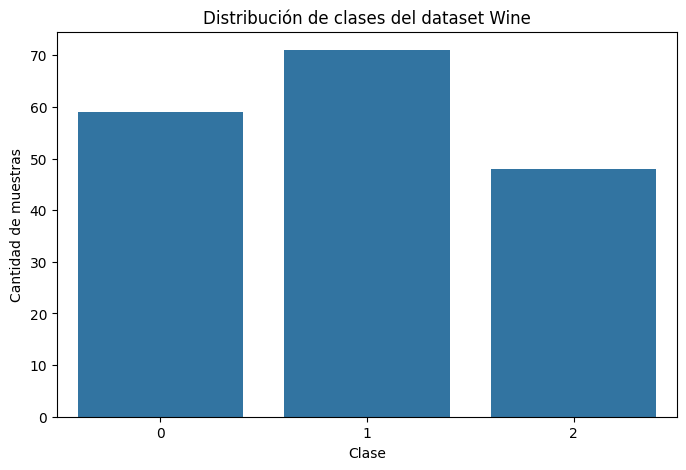

In [103]:
# ==========================================
# CELDA 4: DISTRIBUCION DE CLASES (WINE)
# ==========================================

print("Distribución de clases:")
print(df_wine["Clase"].value_counts().sort_index())

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_wine,
    x="Clase"
)

plt.title("Distribución de clases del dataset Wine")
plt.xlabel("Clase")
plt.ylabel("Cantidad de muestras")

plt.show()

## 3. Wine: separar características, etiquetas y partición Hold Out

In [104]:
# ==========================================
# CELDA 5: SEPARAR X, Y Y DIVISION TRAIN/TEST (WINE)
# ==========================================

# Características químicas y etiquetas
X_wine = df_wine.drop(columns=["Clase", "holdout", "fold"])
y_wine = df_wine["Clase"]

# Partición Hold Out 70/30 definida en el CSV
mascara_train = df_wine["holdout"] == "train"
mascara_test  = df_wine["holdout"] == "test"

X_train = X_wine[mascara_train].values
y_train = y_wine[mascara_train].values
X_test  = X_wine[mascara_test].values
y_test  = y_wine[mascara_test].values

print("Wine - entrenamiento:", X_train.shape, "| prueba:", X_test.shape)
print("Clases en train:", np.bincount(y_train), "| Clases en test:", np.bincount(y_test))

Wine - entrenamiento: (124, 13) | prueba: (54, 13)
Clases en train: [41 50 33] | Clases en test: [18 21 15]


## 4. Dataset sintético: carga y partición Hold Out

In [105]:
# ==========================================
# CELDA 6: CARGAR Y DIVIDIR DATASET SINTETICO
# ==========================================

url_sint = "https://raw.githubusercontent.com/paolamrk/Practica3_MachineLearning/refs/heads/main/sintetico_preparado.csv"

df_sint = pd.read_csv(url_sint)

print("Dimensiones:", df_sint.shape)
print("Columnas:", list(df_sint.columns))

X_sint = df_sint.drop(columns=["Clase", "holdout", "fold"])
y_sint = df_sint["Clase"]

mascara_train_s = df_sint["holdout"] == "train"
mascara_test_s  = df_sint["holdout"] == "test"

Xs_train = X_sint[mascara_train_s].values
ys_train = y_sint[mascara_train_s].values
Xs_test  = X_sint[mascara_test_s].values
ys_test  = y_sint[mascara_test_s].values

print("Sintético - entrenamiento:", Xs_train.shape, "| prueba:", Xs_test.shape)
print("Clases en train:", np.bincount(ys_train), "| Clases en test:", np.bincount(ys_test))

Dimensiones: (1000, 9)
Columnas: ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'Clase', 'holdout', 'fold']
Sintético - entrenamiento: (700, 6) | prueba: (300, 6)
Clases en train: [227 232 241] | Clases en test: [ 98  99 103]


## 5. Escalado de ambos datasets

Los CSV vienen sin normalizar. El `StandardScaler` se ajusta **solo con los datos de entrenamiento** y después se aplica a prueba, para evitar fuga de información (*data leakage*).

In [106]:
# ==========================================
# CELDA 7: ESCALADO (AJUSTE SOLO CON TRAIN)
# ==========================================

# Wine
escalador_wine = StandardScaler().fit(X_train)
X_train_esc = escalador_wine.transform(X_train)
X_test_esc  = escalador_wine.transform(X_test)

# Sintético
escalador_sint = StandardScaler().fit(Xs_train)
Xs_train_esc = escalador_sint.transform(Xs_train)
Xs_test_esc  = escalador_sint.transform(Xs_test)

# Verificación: en train, media ~ 0 y desviación ~ 1
print("Wine train escalado      -> media máx |m|:", np.abs(X_train_esc.mean(axis=0)).max().round(4),
      "| desv. media:", X_train_esc.std(axis=0).mean().round(4))
print("Sintético train escalado -> media máx |m|:", np.abs(Xs_train_esc.mean(axis=0)).max().round(4),
      "| desv. media:", Xs_train_esc.std(axis=0).mean().round(4))

Wine train escalado      -> media máx |m|: 0.0 | desv. media: 1.0
Sintético train escalado -> media máx |m|: 0.0 | desv. media: 1.0


## 6. 1-NN desde cero

In [107]:
# ==========================================
# CELDA 8: CLASE 1-NN DESDE CERO
# ==========================================

class OneNN:
    """Clasificador 1-NN desde cero (distancia euclidiana)."""

    def fit(self, X, y):
        # 1-NN no "aprende" nada: solo guarda el entrenamiento
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        predicciones = []
        for muestra in X:
            # distancia euclidiana a todas las muestras de entrenamiento
            distancias = np.sqrt(np.sum((self.X_train - muestra) ** 2, axis=1))
            # etiqueta del vecino más cercano
            predicciones.append(self.y_train[np.argmin(distancias)])
        return np.array(predicciones)

In [108]:
# ==========================================
# CELDA 9: PRUEBA DE 1-NN (WINE) Y VALIDACION CONTRA SCIKIT-LEARN
# ==========================================

modelo_1nn = OneNN().fit(X_train_esc, y_train)
y_pred_1nn = modelo_1nn.predict(X_test_esc)
print("Exactitud 1-NN (desde cero):", accuracy_score(y_test, y_pred_1nn))

# Validación: scikit-learn se usa solo como referencia, no forma parte de la práctica
ref = KNeighborsClassifier(n_neighbors=1).fit(X_train_esc, y_train)
y_pred_ref = ref.predict(X_test_esc)
print("Exactitud sklearn (referencia):", accuracy_score(y_test, y_pred_ref))
print("¿Mismas predicciones?", np.array_equal(y_pred_1nn, y_pred_ref))

Exactitud 1-NN (desde cero): 0.9629629629629629
Exactitud sklearn (referencia): 0.9629629629629629
¿Mismas predicciones? True


## 7. SVM con scikit-learn

In [109]:
# ==========================================
# CELDA 10: PRUEBA DE SVM (WINE, PARAMETROS POR DEFECTO)
# ==========================================

svm = SVC()   # por defecto: kernel='rbf', C=1.0, gamma='scale'
svm.fit(X_train_esc, y_train)
y_pred_svm = svm.predict(X_test_esc)
print("Exactitud SVM:", accuracy_score(y_test, y_pred_svm))

Exactitud SVM: 0.9814814814814815


In [110]:
# ==========================================
# CELDA 11: CONFIGURACION Y FUNCIONES DE EVALUACION DEL EQUIPO
# ==========================================

import copy
import warnings
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import precision_score, recall_score, f1_score

warnings.filterwarnings("ignore", category=FutureWarning)

SEMILLA   = 42     # semilla común para todo el equipo
TEST_SIZE = 0.30   # Hold Out 70/30
N_FOLDS   = 5      # K-Fold Cross-Validation (k = 5)


def calcular_metricas(y_real, y_pred):
    return {
        "exactitud": accuracy_score(y_real, y_pred),
        "precision": precision_score(y_real, y_pred, average="macro", zero_division=0),
        "recall":    recall_score(y_real, y_pred, average="macro", zero_division=0),
        "f1":        f1_score(y_real, y_pred, average="macro", zero_division=0),
    }


def dividir_holdout(X, y):
    # Partición Hold Out 70/30 estratificada, idéntica para todo el equipo
    return train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEMILLA)


def obtener_kfold():
    return StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEMILLA)


def _entrenar_y_medir(modelo, X_tr, y_tr, X_te, y_te, escalar):
    modelo = copy.deepcopy(modelo)              # modelo nuevo en cada partición
    if escalar:
        escalador = StandardScaler().fit(X_tr)  # se ajusta SOLO con entrenamiento
        X_tr, X_te = escalador.transform(X_tr), escalador.transform(X_te)
    t0 = time.perf_counter(); modelo.fit(X_tr, y_tr)
    t1 = time.perf_counter(); y_pred = modelo.predict(X_te)
    t2 = time.perf_counter()
    res = calcular_metricas(y_te, y_pred)
    res["t_fit_ms"] = (t1 - t0) * 1000
    res["t_pred_ms"] = (t2 - t1) * 1000
    return res, y_pred


def evaluar_holdout(modelo, X, y, escalar=True):
    X, y = np.asarray(X, dtype=float), np.asarray(y)
    X_tr, X_te, y_tr, y_te = dividir_holdout(X, y)
    res, y_pred = _entrenar_y_medir(modelo, X_tr, y_tr, X_te, y_te, escalar)
    return res, (y_te, y_pred)


def evaluar_kfold(modelo, X, y, escalar=True):
    X, y = np.asarray(X, dtype=float), np.asarray(y)
    filas = []
    for tr, te in obtener_kfold().split(X, y):
        res, _ = _entrenar_y_medir(modelo, X[tr], y[tr], X[te], y[te], escalar)
        filas.append(res)
    df = pd.DataFrame(filas)
    resumen = df.mean().to_dict()
    resumen.update({f"{c}_std": df[c].std() for c in ["exactitud", "f1"]})
    return resumen, df

print("Funciones de evaluación listas")

Funciones de evaluación listas


In [111]:
# ==========================================
# CELDA 12: FUNCION DE EVALUACION
# ==========================================

def evaluar_experimento(nombre, modelo, X_train, y_train, X_test, y_test):

    # Medir tiempo de entrenamiento
    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)
    fin_entrenamiento = time.perf_counter()

    # Realizar predicciones
    y_pred = modelo.predict(X_test)
    fin_prediccion = time.perf_counter()

    # Calcular métricas
    metricas = calcular_metricas(y_test, y_pred)

    tiempo_entrenamiento = (fin_entrenamiento - inicio) * 1000
    tiempo_prediccion = (fin_prediccion - fin_entrenamiento) * 1000

    # Mostrar resultados
    print("\n" + "=" * 55)
    print(nombre)
    print("=" * 55)

    print(f"Exactitud:   {metricas['exactitud']:.4f}")
    print(f"Precisión:   {metricas['precision']:.4f}")
    print(f"Recall:      {metricas['recall']:.4f}")
    print(f"F1:          {metricas['f1']:.4f}")

    print(f"Tiempo de entrenamiento: {tiempo_entrenamiento:.4f} ms")
    print(f"Tiempo de predicción:    {tiempo_prediccion:.4f} ms")

    print("\nReporte de clasificación:")
    print(classification_report(y_test, y_pred, zero_division=0))

    # Matriz de confusión
    matriz = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 4))
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Matriz de confusión: {nombre}")
    plt.xlabel("Predicción")
    plt.ylabel("Valor real")
    plt.show()

    # Guardar resultados para la tabla final
    resultado = {
        "Experimento": nombre,
        "Exactitud": metricas["exactitud"],
        "Precisión": metricas["precision"],
        "Recall": metricas["recall"],
        "F1": metricas["f1"],
        "Tiempo entrenamiento (ms)": tiempo_entrenamiento,
        "Tiempo predicción (ms)": tiempo_prediccion
    }

    return resultado


1-NN - Wine
Exactitud:   0.9630
Precisión:   0.9616
Recall:      0.9683
F1:          0.9636
Tiempo de entrenamiento: 0.4801 ms
Tiempo de predicción:    2.9747 ms

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97        18
           1       1.00      0.90      0.95        21
           2       0.94      1.00      0.97        15

    accuracy                           0.96        54
   macro avg       0.96      0.97      0.96        54
weighted avg       0.97      0.96      0.96        54



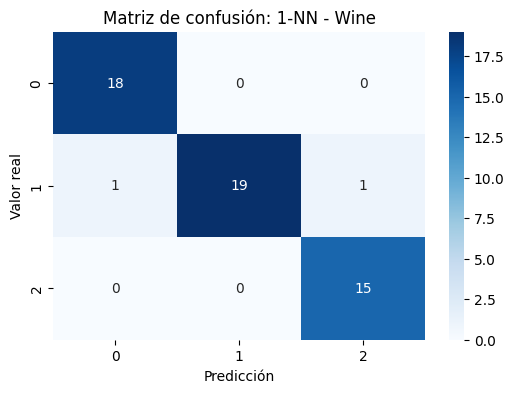

In [112]:
# ==========================================
# CELDA 13: 1-NN - WINE
# ==========================================

resultado_1 = evaluar_experimento(
    "1-NN - Wine",
    OneNN(),
    X_train_esc,
    y_train,
    X_test_esc,
    y_test
)


SVM - Wine
Exactitud:   0.9815
Precisión:   0.9848
Recall:      0.9778
F1:          0.9808
Tiempo de entrenamiento: 4.4634 ms
Tiempo de predicción:    0.5739 ms

Reporte de clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        18
           1       0.95      1.00      0.98        21
           2       1.00      0.93      0.97        15

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54



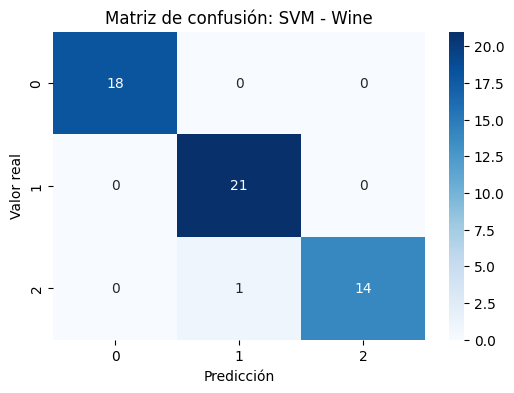

In [113]:
# ==========================================
# CELDA 14: SVM - WINE
# ==========================================

resultado_2 = evaluar_experimento(
    "SVM - Wine",
    SVC(),
    X_train_esc,
    y_train,
    X_test_esc,
    y_test
)


1-NN - Sintético
Exactitud:   0.7967
Precisión:   0.7972
Recall:      0.7977
F1:          0.7966
Tiempo de entrenamiento: 0.0108 ms
Tiempo de predicción:    20.8046 ms

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.82      0.86      0.84        98
           1       0.76      0.80      0.78        99
           2       0.81      0.74      0.77       103

    accuracy                           0.80       300
   macro avg       0.80      0.80      0.80       300
weighted avg       0.80      0.80      0.80       300



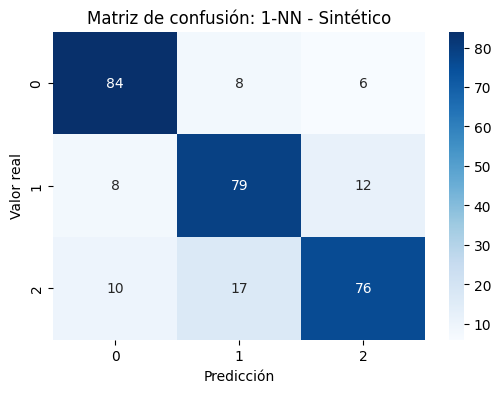

In [114]:
# ==========================================
# CELDA 15: 1-NN - SINTETICO
# ==========================================

resultado_3 = evaluar_experimento(
    "1-NN - Sintético",
    OneNN(),
    Xs_train_esc,
    ys_train,
    Xs_test_esc,
    ys_test
)


SVM - Sintético
Exactitud:   0.8400
Precisión:   0.8406
Recall:      0.8403
F1:          0.8401
Tiempo de entrenamiento: 52.2604 ms
Tiempo de predicción:    25.4436 ms

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.85      0.84      0.85        98
           1       0.82      0.87      0.84        99
           2       0.85      0.82      0.83       103

    accuracy                           0.84       300
   macro avg       0.84      0.84      0.84       300
weighted avg       0.84      0.84      0.84       300



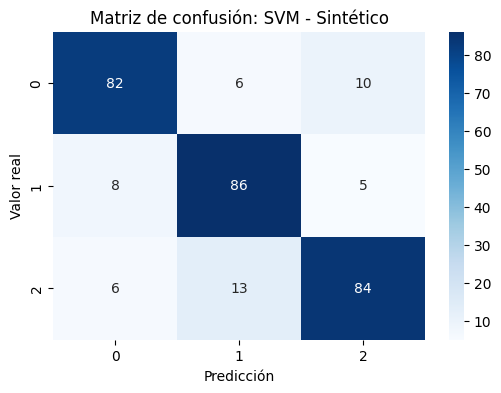

In [115]:
# ==========================================
# CELDA 16: SVM - SINTETICO
# ==========================================

resultado_4 = evaluar_experimento(
    "SVM - Sintético",
    SVC(),
    Xs_train_esc,
    ys_train,
    Xs_test_esc,
    ys_test
)

In [116]:
# ==========================================
# CELDA 17: TABLA COMPARATIVA FINAL
# ==========================================

resultados = pd.DataFrame([
    resultado_1,
    resultado_2,
    resultado_3,
    resultado_4
])

display(
    resultados.style.format({
        "Exactitud": "{:.4f}",
        "Precisión": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "Tiempo entrenamiento (ms)": "{:.4f}",
        "Tiempo predicción (ms)": "{:.4f}"
    })
)

,Experimento,Exactitud,Precisión,Recall,F1,Tiempo entrenamiento (ms),Tiempo predicción (ms)
0,1-NN - Wine,0.9630,0.9616,0.9683,0.9636,0.4801,2.9747
1,SVM - Wine,0.9815,0.9848,0.9778,0.9808,4.4634,0.5739
2,1-NN - Sintético,0.7967,0.7972,0.7977,0.7966,0.0108,20.8046
3,SVM - Sintético,0.8400,0.8406,0.8403,0.8401,52.2604,25.4436


In [117]:
# ==========================================
# CELDA 18: K-FOLD (k = 5) SOBRE EL DATASET COMPLETO
# ==========================================
# Se usan los folds del equipo (StratifiedKFold, shuffle=True, semilla 42) con TODAS
# las muestras de cada dataset. El escalado se ajusta dentro de cada fold.

datasets = {
    "Wine":      (X_wine, y_wine),
    "Sintético": (X_sint, y_sint),
}

modelos = {
    "1-NN (desde cero)": OneNN(),
    "SVM (default)":     SVC(),
}

filas_kfold = []
detalle_kfold = {}   # métricas fold por fold de cada experimento

for nombre_ds, (X, y) in datasets.items():
    for nombre_m, modelo in modelos.items():
        resumen, por_fold = evaluar_kfold(modelo, X, y)
        filas_kfold.append({"dataset": nombre_ds, "modelo": nombre_m, **resumen})
        detalle_kfold[(nombre_ds, nombre_m)] = por_fold

print("K-Fold terminado:", len(filas_kfold), "experimentos")

K-Fold terminado: 4 experimentos


In [118]:
# ==========================================
# CELDA 19: TABLA COMPARATIVA K-FOLD
# ==========================================

tabla_kfold = pd.DataFrame(filas_kfold)

display(
    tabla_kfold.style.format({
        "exactitud":     "{:.4f}",
        "precision":     "{:.4f}",
        "recall":        "{:.4f}",
        "f1":            "{:.4f}",
        "t_fit_ms":      "{:.4f}",
        "t_pred_ms":     "{:.4f}",
        "exactitud_std": "{:.4f}",
        "f1_std":        "{:.4f}"
    })
)

,dataset,modelo,exactitud,precision,recall,f1,t_fit_ms,t_pred_ms,exactitud_std,f1_std
0,Wine,1-NN (desde cero),0.9551,0.9564,0.9603,0.9556,0.0054,0.9124,0.0249,0.0242
1,Wine,SVM (default),0.9833,0.9847,0.9830,0.9834,3.3326,1.7233,0.0248,0.0245
2,Sintético,1-NN (desde cero),0.7960,0.7985,0.7963,0.7956,0.0050,18.5169,0.0222,0.0213
3,Sintético,SVM (default),0.8490,0.8514,0.8488,0.8493,21.1385,5.3230,0.0152,0.0153


In [119]:
# ==========================================
# CELDA 20: DETALLE POR FOLD
# ==========================================

for (nombre_ds, nombre_m), por_fold in detalle_kfold.items():
    print(f"\n{nombre_m} - {nombre_ds}")
    tabla = por_fold.copy()
    tabla.insert(0, "fold", range(1, N_FOLDS + 1))
    display(tabla.round(4))


1-NN (desde cero) - Wine


,fold,exactitud,precision,recall,f1,t_fit_ms,t_pred_ms
0,1,0.9167,0.9221,0.9286,0.9185,0.0059,0.9724
1,2,0.9722,0.9744,0.9762,0.9743,0.0048,0.8919
2,3,0.9722,0.9778,0.9667,0.9710,0.0059,0.9275
3,4,0.9429,0.9410,0.9524,0.9435,0.0052,0.8289
4,5,0.9714,0.9667,0.9778,0.9710,0.0051,0.9415



SVM (default) - Wine


,fold,exactitud,precision,recall,f1,t_fit_ms,t_pred_ms
0,1,0.9444,0.9459,0.9484,0.9458,1.4782,0.4328
1,2,1.0000,1.0000,1.0000,1.0000,1.5824,0.5305
2,3,0.9722,0.9778,0.9667,0.9710,5.9155,4.5980
3,4,1.0000,1.0000,1.0000,1.0000,3.6689,0.4822
4,5,1.0000,1.0000,1.0000,1.0000,4.0179,2.5731



1-NN (desde cero) - Sintético


,fold,exactitud,precision,recall,f1,t_fit_ms,t_pred_ms
0,1,0.820,0.8217,0.8196,0.8196,0.0052,19.8994
1,2,0.800,0.8041,0.8016,0.7994,0.0054,34.3504
2,3,0.805,0.8064,0.8045,0.8034,0.0048,12.5443
3,4,0.760,0.7654,0.7604,0.7616,0.0049,10.8834
4,5,0.795,0.7953,0.7956,0.7940,0.0046,14.9071



SVM (default) - Sintético


,fold,exactitud,precision,recall,f1,t_fit_ms,t_pred_ms
0,1,0.845,0.8480,0.8447,0.8452,15.6981,7.1964
1,2,0.835,0.8352,0.8350,0.8350,14.8197,4.9076
2,3,0.865,0.8690,0.8643,0.8651,18.0329,4.8099
3,4,0.865,0.8683,0.8654,0.8657,25.1416,4.7658
4,5,0.835,0.8365,0.8348,0.8354,32.0004,4.9351


In [120]:
def optimizar_svm(nombre, X_train, y_train, X_test, y_test):

    # Validación cruzada de 5 particiones
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    # Pipeline: escalado y SVM
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC())
    ])

    # Métricas para comparar los modelos
    metricas_cv = {
        "accuracy": "accuracy",
        "precision_macro": "precision_macro",
        "recall_macro": "recall_macro",
        "f1_macro": "f1_macro"
    }

    # 1. Evaluar SVM predeterminado mediante K-Fold
    resultados_default = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=metricas_cv
    )

    # 2. Definir combinaciones de parámetros
    parametros = [
        {
            "svm__kernel": ["linear"],
            "svm__C": [0.1, 1, 10, 100]
        },
        {
            "svm__kernel": ["rbf"],
            "svm__C": [0.1, 1, 10, 100],
            "svm__gamma": ["scale", "auto", 0.01, 0.1, 1]
        }
    ]

    # 3. Buscar la mejor combinación
    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid=parametros,
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    inicio = time.perf_counter()
    busqueda.fit(X_train, y_train)
    tiempo_busqueda = (time.perf_counter() - inicio) * 1000

    mejor_modelo = busqueda.best_estimator_

    # 4. Entrenar SVM predeterminado con todo el train
    modelo_default = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC())
    ])

    inicio = time.perf_counter()
    modelo_default.fit(X_train, y_train)
    tiempo_default = (time.perf_counter() - inicio) * 1000

    # 5. Predecir con ambos modelos sobre el mismo test
    inicio = time.perf_counter()
    pred_default = modelo_default.predict(X_test)
    pred_tuned = mejor_modelo.predict(X_test)
    tiempo_prediccion = (time.perf_counter() - inicio) * 1000

    # 6. Calcular métricas sobre el test
    resultados = []

    for nombre_modelo, pred in [
        ("SVM predeterminado", pred_default),
        ("SVM optimizado", pred_tuned)
    ]:

        resultados.append({
            "Dataset": nombre,
            "Modelo": nombre_modelo,
            "Exactitud": accuracy_score(y_test, pred),
            "Precision": precision_score(
                y_test, pred, average="macro", zero_division=0
            ),
            "Recall": recall_score(
                y_test, pred, average="macro", zero_division=0
            ),
            "F1": f1_score(
                y_test, pred, average="macro", zero_division=0
            )
        })

    print("\n====================================")
    print("OPTIMIZACIÓN SVM:", nombre)
    print("====================================")

    print("\nMejores parámetros encontrados:")
    print(busqueda.best_params_)

    print("\nMejor F1 promedio durante K-Fold:")
    print(round(busqueda.best_score_, 4))

    print("\nTiempo total de búsqueda (ms):")
    print(round(tiempo_busqueda, 2))

    print("\nComparación de métricas en el conjunto de prueba:")
    display(pd.DataFrame(resultados))

    print("\nTiempo de entrenamiento SVM predeterminado (ms):")
    print(round(tiempo_default, 4))

    print("\nTiempo de predicción de ambos modelos (ms):")
    print(round(tiempo_prediccion, 4))

    return {
        "busqueda": busqueda,
        "modelo_default": modelo_default,
        "modelo_optimizado": mejor_modelo,
        "resultados": resultados,
        "tiempo_busqueda": tiempo_busqueda
    }

In [121]:
optimizacion_wine = optimizar_svm(
    "Wine",
    X_train,
    y_train,
    X_test,
    y_test
)


OPTIMIZACIÓN SVM: Wine

Mejores parámetros encontrados:
{'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}

Mejor F1 promedio durante K-Fold:
0.992

Tiempo total de búsqueda (ms):
5832.75

Comparación de métricas en el conjunto de prueba:


,Dataset,Modelo,Exactitud,Precision,Recall,F1
0,Wine,SVM predeterminado,0.981481,0.984848,0.977778,0.980754
1,Wine,SVM optimizado,0.981481,0.984848,0.977778,0.980754



Tiempo de entrenamiento SVM predeterminado (ms):
10.9985

Tiempo de predicción de ambos modelos (ms):
8.2431


In [122]:
optimizacion_sintetico = optimizar_svm(
    "Sintético",
    Xs_train,
    ys_train,
    Xs_test,
    ys_test
)


OPTIMIZACIÓN SVM: Sintético

Mejores parámetros encontrados:
{'svm__C': 10, 'svm__gamma': 0.1, 'svm__kernel': 'rbf'}

Mejor F1 promedio durante K-Fold:
0.8512

Tiempo total de búsqueda (ms):
4812.0

Comparación de métricas en el conjunto de prueba:


,Dataset,Modelo,Exactitud,Precision,Recall,F1
0,Sintético,SVM predeterminado,0.840000,0.840566,0.840319,0.840060
1,Sintético,SVM optimizado,0.836667,0.837121,0.837117,0.836693



Tiempo de entrenamiento SVM predeterminado (ms):
18.4026

Tiempo de predicción de ambos modelos (ms):
14.8645


In [123]:
resultados_optimizacion = []

resultados_optimizacion.extend(
    optimizacion_wine["resultados"]
)

resultados_optimizacion.extend(
    optimizacion_sintetico["resultados"]
)

tabla_optimizacion = pd.DataFrame(resultados_optimizacion)

display(
    tabla_optimizacion.style.format({
        "Exactitud": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}"
    })
)

,Dataset,Modelo,Exactitud,Precision,Recall,F1
0,Wine,SVM predeterminado,0.9815,0.9848,0.9778,0.9808
1,Wine,SVM optimizado,0.9815,0.9848,0.9778,0.9808
2,Sintético,SVM predeterminado,0.8400,0.8406,0.8403,0.8401
3,Sintético,SVM optimizado,0.8367,0.8371,0.8371,0.8367


In [124]:
def medir_complejidad(nombre, X_train, y_train, X_test, modelo_tipo):

    tiempos_entrenamiento = []
    tiempos_prediccion = []

    # Repetir las mediciones para obtener resultados más estables
    repeticiones = 5

    for i in range(repeticiones):

        if modelo_tipo == "1-NN":
            modelo = OneNN()
        else:
            modelo = SVC()

        # Medir entrenamiento
        inicio = time.perf_counter()
        modelo.fit(X_train, y_train)
        fin = time.perf_counter()

        tiempos_entrenamiento.append((fin - inicio) * 1000)

        # Medir predicción
        inicio = time.perf_counter()
        modelo.predict(X_test)
        fin = time.perf_counter()

        tiempos_prediccion.append((fin - inicio) * 1000)

    # Obtener promedios
    promedio_entrenamiento = np.mean(tiempos_entrenamiento)
    promedio_prediccion = np.mean(tiempos_prediccion)

    print("\n====================================")
    print("COMPLEJIDAD EXPERIMENTAL:", nombre)
    print("====================================")

    print("Muestras de entrenamiento:", X_train.shape[0])
    print("Número de características:", X_train.shape[1])
    print("Muestras de prueba:", X_test.shape[0])
    print("Tiempo promedio de entrenamiento:", round(promedio_entrenamiento, 4), "ms")
    print("Tiempo promedio de predicción:", round(promedio_prediccion, 4), "ms")

    # Número de vectores de soporte para SVM
    if modelo_tipo == "SVM":
        print("Número de vectores de soporte:", len(modelo.support_vectors_))

    return {
        "Dataset": nombre,
        "Modelo": modelo_tipo,
        "Muestras entrenamiento": X_train.shape[0],
        "Características": X_train.shape[1],
        "Muestras prueba": X_test.shape[0],
        "Tiempo entrenamiento (ms)": promedio_entrenamiento,
        "Tiempo predicción (ms)": promedio_prediccion
    }

In [125]:
complejidad_1nn_wine = medir_complejidad(
    "Wine",
    X_train_esc,
    y_train,
    X_test_esc,
    "1-NN"
)


COMPLEJIDAD EXPERIMENTAL: Wine
Muestras de entrenamiento: 124
Número de características: 13
Muestras de prueba: 54
Tiempo promedio de entrenamiento: 0.0064 ms
Tiempo promedio de predicción: 2.7433 ms


In [126]:
complejidad_svm_wine = medir_complejidad(
    "Wine",
    X_train_esc,
    y_train,
    X_test_esc,
    "SVM"
)


COMPLEJIDAD EXPERIMENTAL: Wine
Muestras de entrenamiento: 124
Número de características: 13
Muestras de prueba: 54
Tiempo promedio de entrenamiento: 3.9943 ms
Tiempo promedio de predicción: 1.4863 ms
Número de vectores de soporte: 57


In [127]:
complejidad_1nn_sintetico = medir_complejidad(
    "Sintético",
    Xs_train_esc,
    ys_train,
    Xs_test_esc,
    "1-NN"
)


COMPLEJIDAD EXPERIMENTAL: Sintético
Muestras de entrenamiento: 700
Número de características: 6
Muestras de prueba: 300
Tiempo promedio de entrenamiento: 0.0106 ms
Tiempo promedio de predicción: 8.11 ms


In [128]:
complejidad_svm_sintetico = medir_complejidad(
    "Sintético",
    Xs_train_esc,
    ys_train,
    Xs_test_esc,
    "SVM"
)


COMPLEJIDAD EXPERIMENTAL: Sintético
Muestras de entrenamiento: 700
Número de características: 6
Muestras de prueba: 300
Tiempo promedio de entrenamiento: 22.9876 ms
Tiempo promedio de predicción: 10.1665 ms
Número de vectores de soporte: 349


In [129]:
resultados_complejidad = pd.DataFrame([
    complejidad_1nn_wine,
    complejidad_svm_wine,
    complejidad_1nn_sintetico,
    complejidad_svm_sintetico
])

display(
    resultados_complejidad.style.format({
        "Tiempo entrenamiento (ms)": "{:.4f}",
        "Tiempo predicción (ms)": "{:.4f}"
    })
)

,Dataset,Modelo,Muestras entrenamiento,Características,Muestras prueba,Tiempo entrenamiento (ms),Tiempo predicción (ms)
0,Wine,1-NN,124,13,54,0.0064,2.7433
1,Wine,SVM,124,13,54,3.9943,1.4863
2,Sintético,1-NN,700,6,300,0.0106,8.1100
3,Sintético,SVM,700,6,300,22.9876,10.1665
